In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = r"D:\Data Analyst\Data Analyst\Projects\UAE_Supply_Chain_Analytics\01_Raw_Data\UAE_Supply_Chain_Raw.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
df.head()

,Date,SKU_ID,Warehouse_ID,Supplier_ID,Region,Units_Sold,Inventory_Level,Supplier_Lead_Time_Days,Reorder_Point,Order_Quantity,Unit_Cost,Unit_Price,Promotion_Flag,Stockout_Flag,Demand_Forecast
0,2024-01-01,SKU_1,WH_1,SUP_8,West,10,592,14,379,0,13.95,20.48,0,0,8.52
1,2024-01-02,SKU_1,WH_1,SUP_8,West,17,575,14,379,0,13.95,20.48,0,0,18.63
2,2024-01-03,SKU_1,WH_1,SUP_8,North,35,540,14,379,0,13.95,20.48,1,0,39.62
3,2024-01-04,SKU_1,WH_1,SUP_8,South,24,516,14,379,0,13.95,20.48,0,0,19.43
4,2024-01-05,SKU_1,WH_1,SUP_8,West,21,495,14,379,0,13.95,20.48,0,0,18.70


In [6]:
df.shape

(91250, 15)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 91250 entries, 0 to 91249
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Date                     91250 non-null  str    
 1   SKU_ID                   91250 non-null  str    
 2   Warehouse_ID             91250 non-null  str    
 3   Supplier_ID              91250 non-null  str    
 4   Region                   91250 non-null  str    
 5   Units_Sold               91250 non-null  int64  
 6   Inventory_Level          91250 non-null  int64  
 7   Supplier_Lead_Time_Days  91250 non-null  int64  
 8   Reorder_Point            91250 non-null  int64  
 9   Order_Quantity           91250 non-null  int64  
 10  Unit_Cost                91250 non-null  float64
 11  Unit_Price               91250 non-null  float64
 12  Promotion_Flag           91250 non-null  int64  
 13  Stockout_Flag            91250 non-null  int64  
 14  Demand_Forecast          91250 no

In [8]:
# Check missing values in each column

missing_values = df.isnull().sum()

print(missing_values)

Date                       0
SKU_ID                     0
Warehouse_ID               0
Supplier_ID                0
Region                     0
Units_Sold                 0
Inventory_Level            0
Supplier_Lead_Time_Days    0
Reorder_Point              0
Order_Quantity             0
Unit_Cost                  0
Unit_Price                 0
Promotion_Flag             0
Stockout_Flag              0
Demand_Forecast            0
dtype: int64


In [9]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

Date                       0.0
SKU_ID                     0.0
Warehouse_ID               0.0
Supplier_ID                0.0
Region                     0.0
Units_Sold                 0.0
Inventory_Level            0.0
Supplier_Lead_Time_Days    0.0
Reorder_Point              0.0
Order_Quantity             0.0
Unit_Cost                  0.0
Unit_Price                 0.0
Promotion_Flag             0.0
Stockout_Flag              0.0
Demand_Forecast            0.0
dtype: float64


In [10]:
duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 0


In [11]:
df.dtypes

Date                           str
SKU_ID                         str
Warehouse_ID                   str
Supplier_ID                    str
Region                         str
Units_Sold                   int64
Inventory_Level              int64
Supplier_Lead_Time_Days      int64
Reorder_Point                int64
Order_Quantity               int64
Unit_Cost                  float64
Unit_Price                 float64
Promotion_Flag               int64
Stockout_Flag                int64
Demand_Forecast            float64
dtype: object

In [12]:
df.describe()

,Units_Sold,Inventory_Level,Supplier_Lead_Time_Days,Reorder_Point,Order_Quantity,Unit_Cost,Unit_Price,Promotion_Flag,Stockout_Flag,Demand_Forecast
count,91250.000000,91250.000000,91250.000000,91250.000000,91250.000000,91250.000000,91250.000000,91250.000000,91250.0,91250.000000
mean,20.054564,471.522312,7.984000,300.068000,19.272493,12.203320,18.261800,0.101589,0.0,20.082033
std,9.068602,133.488002,3.907929,54.879945,82.340831,4.574982,7.121136,0.302109,0.0,9.503955
min,0.000000,168.000000,2.000000,201.000000,0.000000,5.020000,6.950000,0.000000,0.0,0.000000
25%,13.000000,370.000000,4.000000,252.000000,0.000000,8.180000,12.000000,0.000000,0.0,12.950000
50%,20.000000,461.000000,8.000000,300.000000,0.000000,11.990000,18.180000,0.000000,0.0,19.950000
75%,27.000000,564.000000,11.000000,346.000000,0.000000,16.320000,23.390000,0.000000,0.0,26.930000
max,59.000000,990.000000,14.000000,398.000000,499.000000,19.760000,35.100000,1.000000,0.0,61.420000


In [13]:
# Create a copy of original dataset

df_clean = df.copy()

print("Clean dataset created!")

Clean dataset created!


In [14]:
# Convert Date column to datetime

df_clean['Date'] = pd.to_datetime(df_clean['Date'])

print("Date column converted successfully!")

Date column converted successfully!


In [15]:
print(df_clean['Date'].dtype)

datetime64[us]


In [16]:
print("Start Date:", df_clean['Date'].min())

print("End Date:", df_clean['Date'].max())

Start Date: 2024-01-01 00:00:00
End Date: 2024-12-30 00:00:00


In [17]:
df_clean['Year'] = df_clean['Date'].dt.year

df_clean['Month'] = df_clean['Date'].dt.month

df_clean['Month_Name'] = df_clean['Date'].dt.month_name()

df_clean['Quarter'] = df_clean['Date'].dt.quarter

In [18]:
df_clean['Revenue'] = df_clean['Units_Sold'] * df_clean['Unit_Price']

print("Revenue column created successfully!")
df_clean[['Date', 'SKU_ID', 'Units_Sold', 'Unit_Price', 'Revenue']].head()

Revenue column created successfully!


,Date,SKU_ID,Units_Sold,Unit_Price,Revenue
0,2024-01-01,SKU_1,10,20.48,204.80
1,2024-01-02,SKU_1,17,20.48,348.16
2,2024-01-03,SKU_1,35,20.48,716.80
3,2024-01-04,SKU_1,24,20.48,491.52
4,2024-01-05,SKU_1,21,20.48,430.08


In [19]:
total_revenue = df_clean['Revenue'].sum()

print("Total Revenue:", round(total_revenue, 2), "AED")

Total Revenue: 33426337.22 AED


In [20]:
monthly_revenue = df_clean.groupby(
    ['Year', 'Month', 'Month_Name']
)['Revenue'].sum().reset_index()

monthly_revenue = monthly_revenue.sort_values(
    ['Year', 'Month']
)

monthly_revenue

,Year,Month,Month_Name,Revenue
0,2024,1,January,3224684.78
1,2024,2,February,3596623.24
2,2024,3,March,4232663.58
3,2024,4,April,4089320.27
4,2024,5,May,3851210.26
5,2024,6,June,3100546.96
6,2024,7,July,2470711.65
7,2024,8,August,1811864.31
8,2024,9,September,1385993.27
9,2024,10,October,1455408.84


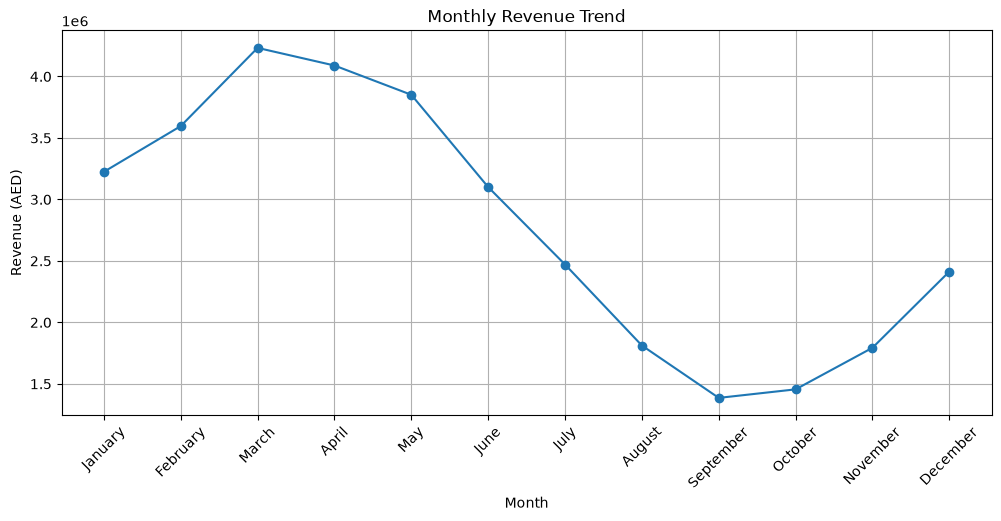

In [22]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue['Month_Name'],
    monthly_revenue['Revenue'],
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (AED)')
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [23]:
warehouse_inventory = df_clean.groupby('Warehouse_ID').agg(
    Total_Inventory=('Inventory_Level', 'sum'),
    Average_Inventory=('Inventory_Level', 'mean'),
    Total_Units_Sold=('Units_Sold', 'sum')
).reset_index()

warehouse_inventory

,Warehouse_ID,Total_Inventory,Average_Inventory,Total_Units_Sold
0,WH_1,8505526,466.056219,366902
1,WH_2,8969686,491.489644,366078
2,WH_3,8313953,455.559068,366110
3,WH_4,8712373,477.390301,365775
4,WH_5,8524873,467.116329,365114


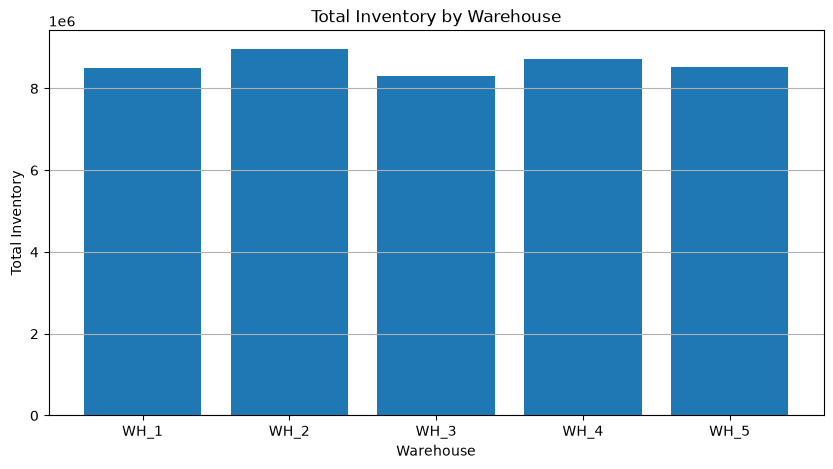

In [24]:
plt.figure(figsize=(10, 5))

plt.bar(
    warehouse_inventory['Warehouse_ID'].astype(str),
    warehouse_inventory['Total_Inventory']
)

plt.title('Total Inventory by Warehouse')
plt.xlabel('Warehouse')
plt.ylabel('Total Inventory')
plt.grid(axis='y')

plt.show()

In [25]:
supplier_performance = df_clean.groupby('Supplier_ID').agg(
    Total_Orders=('Order_Quantity', 'sum'),
    Average_Lead_Time=('Supplier_Lead_Time_Days', 'mean'),
    Total_Units_Sold=('Units_Sold', 'sum'),
    Average_Unit_Cost=('Unit_Cost', 'mean')
).reset_index()

supplier_performance = supplier_performance.round(2)

supplier_performance

,Supplier_ID,Total_Orders,Average_Lead_Time,Total_Units_Sold,Average_Unit_Cost
0,SUP_1,195080,8.11,204249,11.85
1,SUP_10,189525,7.41,197242,12.53
2,SUP_2,184645,8.42,190999,11.39
3,SUP_3,161721,8.26,168017,11.97
4,SUP_4,176568,8.64,183147,13.26
5,SUP_5,162347,6.96,168145,10.96
6,SUP_6,141361,7.90,146684,12.88
7,SUP_7,239283,7.56,248830,11.64
8,SUP_8,196023,8.50,205407,14.22
9,SUP_9,112062,8.19,117259,10.88


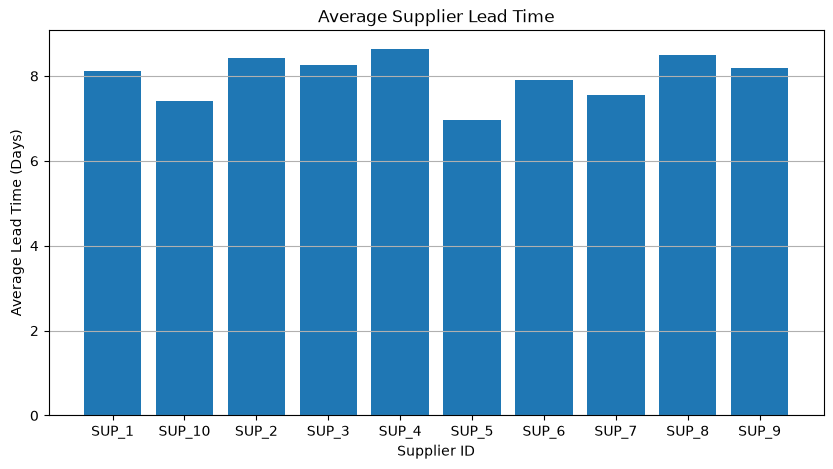

In [26]:
plt.figure(figsize=(10, 5))

plt.bar(
    supplier_performance['Supplier_ID'].astype(str),
    supplier_performance['Average_Lead_Time']
)

plt.title('Average Supplier Lead Time')
plt.xlabel('Supplier ID')
plt.ylabel('Average Lead Time (Days)')
plt.grid(axis='y')

plt.show()

In [27]:
df_clean['Stock_Status'] = np.where(
    df_clean['Inventory_Level'] <= df_clean['Reorder_Point'],
    'Reorder Required',
    'Stock Available'
)

df_clean['Stock_Status'].value_counts()

Stock_Status
Stock Available     86209
Reorder Required     5041
Name: count, dtype: int64

In [28]:
reorder_summary = df_clean.groupby('Stock_Status').agg(
    Total_Records=('SKU_ID', 'count'),
    Total_Units_Sold=('Units_Sold', 'sum'),
    Average_Inventory=('Inventory_Level', 'mean')
).reset_index()

reorder_summary.round(2)

,Stock_Status,Total_Records,Total_Units_Sold,Average_Inventory
0,Reorder Required,5041,122591,288.74
1,Stock Available,86209,1707388,482.21


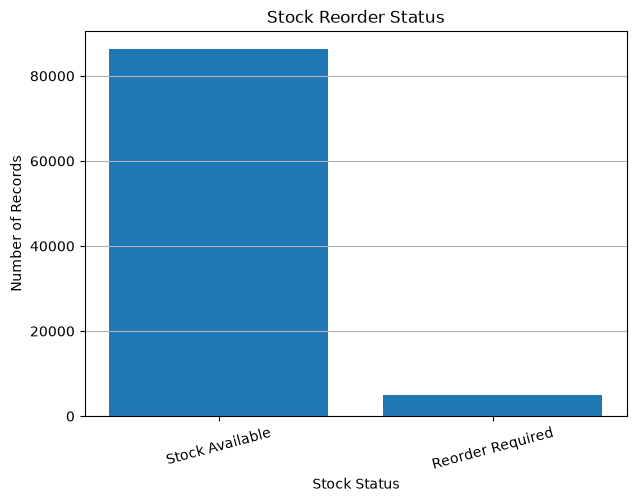

In [29]:
stock_counts = df_clean['Stock_Status'].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(stock_counts.index, stock_counts.values)

plt.title('Stock Reorder Status')
plt.xlabel('Stock Status')
plt.ylabel('Number of Records')
plt.xticks(rotation=15)
plt.grid(axis='y')

plt.show()

In [30]:
print("Final Dataset Shape:", df_clean.shape)

print("\nColumn Names:")
print(df_clean.columns.tolist())

print("\nMissing Values:")
print(df_clean.isnull().sum().sum())

df_clean.head()

Final Dataset Shape: (91250, 21)

Column Names:
['Date', 'SKU_ID', 'Warehouse_ID', 'Supplier_ID', 'Region', 'Units_Sold', 'Inventory_Level', 'Supplier_Lead_Time_Days', 'Reorder_Point', 'Order_Quantity', 'Unit_Cost', 'Unit_Price', 'Promotion_Flag', 'Stockout_Flag', 'Demand_Forecast', 'Year', 'Month', 'Month_Name', 'Quarter', 'Revenue', 'Stock_Status']

Missing Values:
0


,Date,SKU_ID,Warehouse_ID,Supplier_ID,Region,Units_Sold,Inventory_Level,Supplier_Lead_Time_Days,Reorder_Point,Order_Quantity,...,Unit_Price,Promotion_Flag,Stockout_Flag,Demand_Forecast,Year,Month,Month_Name,Quarter,Revenue,Stock_Status
0,2024-01-01,SKU_1,WH_1,SUP_8,West,10,592,14,379,0,...,20.48,0,0,8.52,2024,1,January,1,204.80,Stock Available
1,2024-01-02,SKU_1,WH_1,SUP_8,West,17,575,14,379,0,...,20.48,0,0,18.63,2024,1,January,1,348.16,Stock Available
2,2024-01-03,SKU_1,WH_1,SUP_8,North,35,540,14,379,0,...,20.48,1,0,39.62,2024,1,January,1,716.80,Stock Available
3,2024-01-04,SKU_1,WH_1,SUP_8,South,24,516,14,379,0,...,20.48,0,0,19.43,2024,1,January,1,491.52,Stock Available
4,2024-01-05,SKU_1,WH_1,SUP_8,West,21,495,14,379,0,...,20.48,0,0,18.70,2024,1,January,1,430.08,Stock Available


In [31]:
output_path = r"D:\Data Analyst\Data Analyst\Projects\UAE_Supply_Chain_Analytics\02_Cleaned_Data\UAE_Supply_Chain_Cleaned.csv"

df_clean.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")
print(output_path)

Cleaned dataset saved successfully!
D:\Data Analyst\Data Analyst\Projects\UAE_Supply_Chain_Analytics\02_Cleaned_Data\UAE_Supply_Chain_Cleaned.csv
